In [1]:
%cd ..

/Users/maksimshmalts/Documents/DieKonstraintsPrivat/comp_modeling


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from itertools import product
import json
from typing import List

from data_utils.load_datasets import load_constraints, save_tsv_generic
from comp_modeling.compxconstraints import CompXConstraints, DEF_ID

Load GermaNet data...: 100%|█████████▉| 99.99999999999996/100 [00:04<00:00, 22.31it/s] 
Load Wiktionary data...: 100%|██████████| 100.0/100 [00:00<00:00, 1016.74it/s]
Load Ili records...: 100%|██████████| 100.0/100 [00:00<00:00, 258907.65it/s]


In [3]:
constr_path = "constraints/constraints_all_revised.yaml"
constraints = load_constraints(constr_path)

In [4]:
with open("out/acceptable_linkers.json", encoding="utf-8") as i:
    acceptable_linkers_all = json.load(i)

with open("out/unacceptable_linkers.json", encoding="utf-8") as i:
    unacceptable_linkers_all = json.load(i)

In [5]:
used_constrs = set()
for acceptable_linkers in acceptable_linkers_all.values():
    for linker, constrs in acceptable_linkers.items():
        used_constrs.update(constrs)
for unacceptable_linkers in unacceptable_linkers_all.values():
    for linker, constrs in unacceptable_linkers.items():
        used_constrs.update(constrs)

used_constrs = list(used_constrs)

involved_domains_data = defaultdict(lambda: defaultdict(int))
linkers_by_domains_data = defaultdict(lambda: defaultdict(list))
for c_id in used_constrs:
    if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
        key = ("gen", "ours")
    else:
        key = ("restr", "ours")
    domains = constraints[c_id]["domain_type"]
    for domain in domains:
        involved_domains_data[domain][key] += 1
    if key == ("gen", "ours"):
        domains_str = "+".join(sorted(domains))
        constr_acc_linkers = CompXConstraints.esc_batch(constraints[c_id]["acceptable_linkers"])
        for linker in constr_acc_linkers:
            linkers_by_domains_data[linker][(domains_str, "constraints")].append(c_id)
            

involved_domains_df = pd.DataFrame(involved_domains_data).fillna(0).astype(int)
# involved_domains_df.insert(0, "total", involved_domains_df.sum(axis=1))
involved_domains_df = involved_domains_df.T
involved_domains_df.drop("default", inplace=True)

In [6]:
used_constrs_ref = [
    c_id for c_id, constr in constraints.items()
    if constr["measures"] != "NA" and
    constr["measures"]["regularity"]["item"] >= 0.5
]

involved_domains_ref_data = defaultdict(lambda: defaultdict(int))
for c_id in used_constrs_ref:
    if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
        key = ("gen", "reference")
    else:
        key = ("restr", "reference")
    for domain in constraints[c_id]["domain_type"]:
        involved_domains_ref_data[domain][key] += 1

involved_domains_ref_df = pd.DataFrame(involved_domains_ref_data).fillna(0).astype(int)
involved_domains_ref_df = involved_domains_ref_df.T
involved_domains_ref_df.drop("default", inplace=True)

Our dataset consists of ~900 compounds with all implemented constraints defined over them. We derived it by intersecting the items of _GeCoDB\_v07\_GN_ and _SP18\_Pl\_Constr_. Since Schäfer & Pankratz 2018 targeted nouns that exhibit an alternation between a pluralic and a non-pluralic linker, _SP18\_Pl\_Constr_ (hence, our modeling dataset) mostly contains simplex masculine and neutral nouns, which prevail among compounds that satisfy this condition. This leads to a noticeable limitation of the dataset: phonological and especially derivational constraints are largely underused in it. Thus, only $62\%$ and $20\%$ of these constraints, respectively, enter the modeling of this dataset. Given that these are the most productive source of _-s-_, this linker is underrepresented in the dataset.

This modeling dataset, then, cannot reflect the actual complexity of German nominal compounding, and cannot be used to build the final German compounding model. However, its simplified constraint interaction provide a favorable ground for the first attempts of modeling German compounding. By focusing on a single morphology vs. semantics interaction, we will not be overwhelmed by the diversity and the number of constraint conflicts. We will therefore be able to produce first insights about constraint conflict resolution and work out a direction for future research. The small size of the dataset will allow for more detailed inspection of the results. Finally, a sane presence of the restrictive constraints will let us investigate constraint elimination to a satisfactory extent. Overall, we suppose that our modeling dataset is a great baseline for the initial findings.

In [8]:
involved_domains_comparison_df = pd.concat((involved_domains_ref_df, involved_domains_df), axis=1)
for key in ["gen", "restr"]:
    involved_domains_comparison_df[(key, "%")] = (100 * (
        involved_domains_comparison_df[(key, "ours")] /
        involved_domains_comparison_df[(key, "reference")]
    )).fillna(100).astype(int)
involved_domains_comparison_df = involved_domains_comparison_df[
    sorted(involved_domains_comparison_df.columns)
]

save_tsv_generic(involved_domains_comparison_df, "out/involved_domains_comparison_df.tsv")
involved_domains_comparison_df

gen                restr               
                 % ours reference     % ours reference
morphological   80   16        20   100    8         8
derivational    20    2        10   100    7         7
semantic        90   10        11   100    0         0
phonological    62    5         8    85    6         7
lexical        100    0         0   100    1         1

Pluralic linkers _-e-_, _-"e-_, and _-"0-_ are only ever produced by targeted semantics-involving constraints. Linker _-"er-_ is produced by two targeted semantics-involving constraint and one multi-linker non-semantic constraint. Linker _-en-_ is produced by one targeted semantics-involving constraint, one targeted non-semantic constraints, and two multi-linker non-semantic constraints. In sum, four out of five pluralic linkers are only produced by semantic constraints if we ignore multi-linker constraints. If we include multi-linker constraints back into account, three pluralic linkers are still only produced by semantic constraints. In other words, if we exclude semantics-involving constraints from consideration, we will realistically only be able to produce _-0-_, _-s-_, _-en-_, and maybe _-"er-_.* Indeed, in a dedicated substudy, we predicted the linkers for the entries of the _GeCoDB\_v07\_GN_ dataset, for which the semantic constraints are undefined, using the Albright & Hayes 2002 method. From ~49k trials, only _-0-_, _-s-_, and _-en-_ were ever produced.

This poses a paradox and a modeling challenge for nominal compounding. While the semantic constraints are much less regular, and semantics seems to be only a soft cue in German compounding, it is responsible for at least half of the linker inventory. While the number of the affected compounds is relatively small, it is non-negligible and, and these compounds cannot be conveniently accomodated as exceptions.

\* Note that this would have been the case even if all the constraints were active over the dataset. The missing constraints can only produce _-0-_, _-s-_, and _-en-_, themselves.

In [9]:
unused_constrs = list(set(used_constrs_ref) - set(used_constrs))
unproduced_linkers = set()
for c_id in unused_constrs:
    unproduced_linkers.update(
        CompXConstraints.esc_batch(constraints[c_id]["acceptable_linkers"]
    ))

unproduced_linkers

{'_', '_+en_', '_+s_'}

In [58]:
linkers_by_domains_df = pd.DataFrame(linkers_by_domains_data)
linkers_by_domains_df.drop(("default", "constraints"), inplace=True)
linkers_by_domains_df = linkers_by_domains_df.T
keys = sorted(linkers_by_domains_df.columns.levels[0], key=lambda x: ("morph" in x), reverse=True)
keys.remove("morphological")
keys.remove("morphological+semantic")
keys = ["morphological", "morphological+semantic"] + keys
keys.remove("default")
col_order = []
for key in keys:
    linkers_by_domains_df[key, "n"] = linkers_by_domains_df[key, "constraints"].map(
        lambda x: len(x) if isinstance(x, list) else 0
    )
    linkers_by_domains_df[key, "constraints"] = linkers_by_domains_df[key, "constraints"].map(
        lambda x: ", ".join(x) if isinstance(x, list) else ""
    )
    col_order.extend([(key, "n"), (key, "constraints")])
linkers_by_domains_df = linkers_by_domains_df[col_order]

save_tsv_generic(linkers_by_domains_df, "out/linkers_by_domains_df.tsv")
linkers_by_domains_df

morphological                                                     \
                   n                                        constraints   
_                  5  p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:pl:#e_u...   
_+e_               0                                                      
_+=er_             1                   p2l:decl_cl:pl:#er-0/er|def-0/er   
_+s_               1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+=_               0                                                      
_+en_              1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+=e_              0                                                      

       morphological+semantic  \
                            n   
_                           2   
_+e_                        1   
_+=er_                      2   
_+s_                        0   
_+=_                        1   
_+en_                       1   
_+=e_                       1   

                                                           \
                                              constraints   
_       p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, p2l:dec...   
_+e_                     p2l:decl_cl:pl:#e-0|pl_interpr-e   
_+=er_  p2l:decl_cl:pl:#er-0/er|anim-er, p2l:decl_cl:p...   
_+s_                                                        
_+=_             p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml   
_+en_              p2l:decl_cl:mixed-0/s/en|pl_interpr-en   
_+=e_            p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml   

       morphological+phonological  \
                                n   
_                               1   
_+e_                            0   
_+=er_                          0   
_+s_                            1   
_+=_                            0   
_+en_                           1   
_+=e_                           0   

                                                     \
                                        constraints   
_       p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+e_                                                  
_+=er_                                                
_+s_    p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+=_                                                  
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+=e_                                                 

       morphological+phonological+semantic  \
                                         n   
_                                        0   
_+e_                                     0   
_+=er_                                   0   
_+s_                                     0   
_+=_                                     0   
_+en_                                    2   
_+=e_                                    0   

                                                          derivational  \
                                              constraints            n   
_                                                                    0   
_+e_                                                                 0   
_+=er_                                                               0   
_+s_                                                                 2   
_+=_                                                                 0   
_+en_   l2p:en|non_par_m, p2l:phon_fin:weak_F_cons$-0/...            0   
_+=e_                                                                0   

                                                      phonological  \
                                          constraints            n   
_                                                                1   
_+e_                                                             0   
_+=er_                                                           0   
_+s_    p2l:drv:sfx:sfx-s|def-s, p2l:drv:prx_deverb-s            0   
_+=_                                                             0   
_+en_                                                            1   
_+=e_      

In [60]:
linkers_by_domains_df[[col for col in linkers_by_domains_df.columns if not "sem" in col[0]]]

morphological                                                     \
                   n                                        constraints   
_                  5  p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:pl:#e_u...   
_+e_               0                                                      
_+=er_             1                   p2l:decl_cl:pl:#er-0/er|def-0/er   
_+s_               1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+=_               0                                                      
_+en_              1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+=e_              0                                                      

       morphological+phonological  \
                                n   
_                               1   
_+e_                            0   
_+=er_                          0   
_+s_                            1   
_+=_                            0   
_+en_                           1   
_+=e_                           0   

                                                    derivational  \
                                        constraints            n   
_       p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            0   
_+e_                                                           0   
_+=er_                                                         0   
_+s_    p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            2   
_+=_                                                           0   
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            0   
_+=e_                                                          0   

                                                      phonological  \
                                          constraints            n   
_                                                                1   
_+e_                                                             0   
_+=er_                                                           0   
_+s_    p2l:drv:sfx:sfx-s|def-s, p2l:drv:prx_deverb-s            0   
_+=_                                                             0   
_+en_                                                            1   
_+=e_                                                            0   

                                       
                          constraints  
_            p2l:phon_fin:sibilant$-0  
_+e_                                   
_+=er_                                 
_+s_                                   
_+=_                                   
_+en_   p2l:phon_fin:schwa$-en|def-en  
_+=e_

The absolute majority of the compounds are covered by 2-5 generative constraints, with mean of $3.4$ and mode of $2$. Not all of these constraints necessarily conflict within one compound. On average, every $\sim 2$ constraints potentially applicable to one compound actually generate the same linker. This begs the question whether these constraints cooperate during linker generation and jointly increase the probability of their linker.

While in a considerable amount of compounds, these (potentially) cooperating constraints converge to a single generated linker, the constraints generate two linkers for most of the compounds, and even three for some of them (mean, $1.8$, mode $2$).

Remember that these number are observed over a modeling dataset with a simplified constraint interaction. The real picture must be more intricate. But again, simplicity is a virtue at this initial attempt to model German compounding: it will be much easier to grasp the first patterns of it from the two-linker outputs.

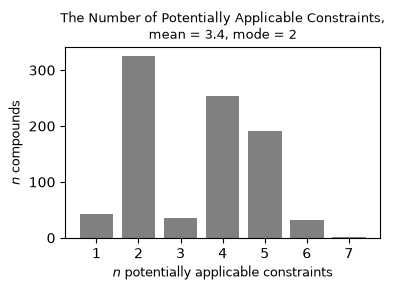

In [ ]:
n_constr = [
    sum([len(c_ids) for c_ids in constrs.values()])
    for constrs in acceptable_linkers_all.values()
]

uc_c = np.unique_counts(n_constr)
x_c = uc_c.values
y_c = uc_c.counts

mean = np.mean(n_constr).round(1)
mode = x_c[y_c.argmax()]

plt.figure(figsize=(4, 3))
plt.bar(x_c, y_c, color="grey")
plt.xlabel(r"$n$ potentially applicable constraints", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Potentially Applicable Generative Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_c)

plt.tight_layout()
plt.savefig("out/n_constrs.png", dpi="figure")
plt.show()

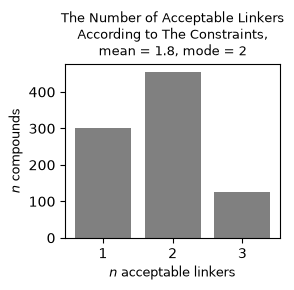

In [5]:
n_accept_linkers = [
    len(accept_linkers)
    for accept_linkers in acceptable_linkers_all.values()
]

uc_l = np.unique_counts(n_accept_linkers)
x_l = uc_l.values
y_l = uc_l.counts

mean = np.mean(n_accept_linkers).round(1)
mode = x_l[y_l.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_l, y_l, color="grey")
plt.xlabel(r"$n$ acceptable linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Acceptable Linkers\nAccording to The Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_l)

plt.tight_layout()
plt.savefig("out/n_acceptable_linkers.png", dpi="figure")
plt.show()

In [6]:
(np.array(n_constr) / np.array(n_accept_linkers)).mean().round(1).item()

1.9

In [7]:
def get_n1s_by_n_constr(n: int) -> List[str]:
    indices = np.where(np.array(n_constr) == n)[0]
    comps = np.array(
        list(acceptable_linkers_all.keys())
    )[indices].tolist()
    n1s = [comp.split("_")[0] for comp in comps]
    unique_n1s = list(set(n1s))
    comp_examples = [comps[n1s.index(n1)] for n1 in unique_n1s]
    return unique_n1s, comp_examples

In [8]:
geco2text = lambda linker: (
    "-" + linker.replace("_", "").replace("+", "").replace("=", "\"") + "-"
    if linker.count("_") == 2 else "0"
)
n_constr_df_data = {}
for i in x_c:
    n1s, examples = get_n1s_by_n_constr(i)
    for n1, example in zip(n1s, examples):
        acceptable_linkers = acceptable_linkers_all[example]
        constrs_n1 = []
        for constrs in acceptable_linkers.values():
            constrs_n1.extend(constrs)
        constrs_n1_str = ", ".join(sorted(constrs_n1))
        accept_linkers_str = ", ".join(
            geco2text(linker) for linker in acceptable_linkers.keys()
        )
        record = {
            "acceptable_linkers": accept_linkers_str,
            "example": example,
            "constraints": constrs_n1_str
        }
        n_constr_df_data[(n1, i)] = record

n_constr_df = pd.DataFrame(n_constr_df_data).T.sort_index()
n_constr_df

acceptable_linkers                  example  \
apfel     2                  0               apfel_baum   
bad       4           0, -"er-     bad_+=er_architektur   
ball      2                  0              ball_besitz   
bett      4       0, -s-, -en-              bett_wäsche   
          5       0, -s-, -en-            bett_+en_zahl   
bild      4           0, -"er-            bild_qualität   
brett     5           0, -"er-           brett_+er_bude   
buch      4           0, -"er-              buch_handel   
ei        4           0, -"er-                  ei_gelb   
          5           0, -"er-                ei_sprung   
frau      1                  0            frau_+en_arzt   
gerät     2                  0            gerät_+e_haus   
geräusch  4             0, -s-         geräusch_dämmung   
geschenk  3             0, -s-            geschenk_idee   
          4        0, -e-, -s-        geschenk_+e_liste   
gitarre   2            0, -en-          gitarre_+n_riff   
hand      2                  0              hand_gelenk   
haus      5           0, -"er-                haus_tier   
hemd      4       0, -s-, -en-              hemd_tasche   
hund      4       0, -e-, -en-           hund_+e_halter   
katze     2            0, -en-             katze_+n_klo   
kind      5           0, -"er-          kind_+er_zimmer   
lied      4           0, -"er-          lied_+er_macher   
mutter    2                  0           mutter_sprache   
          3             0, -"-          mutter_+=_treff   
nagel     2                  0               nagel_lack   
nation    7       0, -s-, -en-       nation_+en_wertung   
ohr       4       0, -s-, -en-                ohr_feige   
person    5       0, -s-, -en-         person_+en_kreis   
          6       0, -s-, -en-  person_+en_gesellschaft   
rad       4           0, -"er-                rad_stand   
schloss   5           0, -"er-             schloss_park   
schwert   4           0, -"er-          schwert_kämpfer   
schwester 5       0, -s-, -en-        schwester_+n_paar   
          6       0, -s-, -en-         schwester_modell   
sonne     2            0, -en-          sonne_+n_strahl   
stadt     2                  0             stadt_gebiet   
          3            0, -"e-  stadt_+=e_partnerschaft   
vater     2                  0                vater_tag   
vogel     2                  0                vogel_art   
          3             0, -"-                vogel_zug   
weg       2                  0              weg_strecke   
          3             0, -e-              weg_+e_netz   
wurm      6     0, -"er-, -en-              wurm_befall   
zahn      2                  0                zahn_arzt   
          3            0, -"e-             zahn_wechsel   

                                                   constraints  
apfel     2               def-0, p2l:decl_cl:pl:#0_uml-0|def-0  
bad       4  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
ball      2               def-0, p2l:decl_cl:pl:#e_uml-0|def-0  
bett      4  def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en, p2...  
          5  def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en, p2...  
bild      4  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
brett     5  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
buch      4  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
ei        4  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
          5  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
frau      1                                              def-0  
gerät     2                   def-0, p2l:decl_cl:pl:#e-0|def-0  
geräusch  4  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:drv:prx_...  
geschenk  3  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:drv:prx_...  
          4  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:...  
gitarre   2               def-0, p2l:phon_fin:schwa$-en|def-en  
hand      2               def-0, p2l:decl_cl:pl:#e_uml-0|def-0  
haus      5  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
hem

NB! Some of the linkers are undefined.

In [ ]:
n_constr_df_data = {}
for i in 

In [33]:
get_n1s_by_n_constr(1)

(['frau'], ['frau_+en_arzt'])

In [34]:
get_n1s_by_n_constr(2)

(['stadt',
  'katze',
  'vogel',
  'hand',
  'ball',
  'gitarre',
  'apfel',
  'vater',
  'sonne',
  'zahn',
  'weg',
  'mutter',
  'nagel',
  'gerät'],
 ['stadt_gebiet',
  'katze_+n_klo',
  'vogel_art',
  'hand_gelenk',
  'ball_besitz',
  'gitarre_+n_riff',
  'apfel_baum',
  'vater_tag',
  'sonne_+n_strahl',
  'zahn_arzt',
  'weg_strecke',
  'mutter_sprache',
  'nagel_lack',
  'gerät_+e_haus'])

In [35]:
get_n1s_by_n_constr(3)

(['stadt', 'vogel', 'zahn', 'weg', 'mutter', 'geschenk'],
 ['stadt_+=e_partnerschaft',
  'vogel_zug',
  'zahn_wechsel',
  'weg_+e_netz',
  'mutter_+=_treff',
  'geschenk_idee'])

In [30]:
get_n1s_by_n_constr(4)

['rad',
 'bad',
 'hund',
 'buch',
 'geschenk',
 'hemd',
 'lied',
 'geräusch',
 'bild',
 'schwert',
 'ohr',
 'ei',
 'bett']

In [31]:
get_n1s_by_n_constr(5)

['haus', 'kind', 'brett', 'schwester', 'schloss', 'ei', 'bett', 'person']

In [4]:
# from main.py
methods = ["albright-hayes", "yang-cond", "yang-cvg"]
s = lambda x: "+" if x else "-"
keys = [
    f"{s(count_def)}count_def|{s(coop)}coop|{s(l2p)}l2p"
    for count_def, coop, l2p in product([True, False], repeat=3)
]

In [4]:
metrics_summary = load_tsv_generic("out/metrics_summary.tsv")
metrics_summary

,acc,f1
yang-cvg,0.715,0.446
yang-cond,0.713,0.397
albright-hayes,0.667,0.230
rand,0.375,0.128
zero,0.570,0.104


### Albright & Hayes 2002

* The three first best results include the 

In [5]:
method_dir = os.path.join(outdir, "albright-hayes")

In [6]:
# * Three worst results are with -l2p
# * Cooperation does not improve the scores
# * The low metrics are caused by vistually absent
# possibility to produce pluralic linkers due to
# the low regularity of the semantic constraints
metric_summary_ah02 = load_tsv_generic(os.path.join(method_dir, "metrics_summary.tsv"))
metric_summary_ah02

,acc,f1,is_best_key
+count_def|+coop|+l2p,0.667,0.230,True
+count_def|+coop|-l2p,0.667,0.230,False
+count_def|-coop|+l2p,0.667,0.230,False
-count_def|+coop|+l2p,0.667,0.230,False
-count_def|-coop|+l2p,0.667,0.230,False
-count_def|+coop|-l2p,0.667,0.223,False
+count_def|-coop|-l2p,0.660,0.221,False
-count_def|-coop|-l2p,0.660,0.221,False


In [7]:
ldistr_comparison = load_tsv_generic(os.path.join(method_dir, "ldistr_comparison.tsv"))
f1_acc_df = load_tsv_generic(os.path.join(method_dir, "f1_acc_df.tsv"))
cnf_matrix = load_tsv_generic(os.path.join(method_dir, "confusion_matrix.tsv"))

AH02 overproduces a zero linker and underproduces _-en-_ and _-"er-_. All the other linkers are never produced (except for _-s-_ which is produced a negligible number of times).

In [8]:
ldistr_comparison

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+s_,0.015,0.001
_+=_,0.007,0.000


This consequently leads to a zero accuracy and F1 score over the four non-produced linkers, and a low recall (hence, F1 score) over the two underproduced linkers. While having a great recall for a zero linker, AH02 is not very precise over it. Overall, the low F1 score is explained by the underrepresentedness of most of the linkers and overfavoring the zero.

In [9]:
f1_acc_df

,acc,f1,N,prec,recall
avg,0.667,0.230,882.0,0.327,0.224
_,0.982,0.771,503.0,0.635,0.982
_+en_,0.476,0.642,164.0,0.987,0.476
_+=er_,0.113,0.194,141.0,0.667,0.113
_+e_,0.000,0.000,42.0,0.000,0.000
_+=e_,0.000,0.000,13.0,0.000,0.000
_+s_,0.000,0.000,13.0,0.000,0.000
_+=_,0.000,0.000,6.0,0.000,0.000


The overproduction of zero originates from the four non-produced linkers: they were all false predicted as zero.

In [10]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


Correspondingly, the constraint(s) for the zero linker must always win the ones for _"0_, _-s-_, _-"e_, and _-e_. Let's investigate the constraint conflicts and their resolution under AH02 to understand why this is the case.

### Short Demonstration of `CompXConstraints`

##### 'Kinderwagen'

In [4]:
comp_gecodb = "kind_+er_wagen"
appl_row = appl_ind.loc[comp_gecodb]
cxc = CompXConstraints(appl_row)
cxc.true

'_+=er_'

In [5]:
cxc.acceptable_linkers

defaultdict(list,
            {'_': ['def-0',
              'p2l:decl_cl:pl:#er-0/er|def-0/er',
              'p2l:decl_cl:pl:#er-0/er|!pl_interpr-0'],
             '_+=er_': ['p2l:decl_cl:pl:#er-0/er|def-0/er',
              'p2l:decl_cl:pl:#er-0/er|anim-er']})

In [6]:
cxc.unacceptable_linkers

defaultdict(list,
            {'_+s_': ['l2p:s|tend_cmpx_morph', 'l2p:s|tend_cmpx_phon'],
             '_+en_': ['l2p:en|par'],
             '_+e_': ['l2p:e|par'],
             '_+=e_': ['l2p:e_uml'],
             '_+=_': ['l2p:0_uml']})

In [7]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=False,
    constr_cooperation=False,
    restrict_with_l2p=False
)

cxc.gen_constr_df

,linker,condition,spec_score,cvg,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#er-0/er|!pl_interpr-0,_,[PL:er] & [sem:!PL],25.2,0.171,0.622,0.6220
p2l:decl_cl:pl:#er-0/er|anim-er,_+=er_,[PL:er] & [[sem:anim] | [sem:pers]],28.0,0.003,0.501,0.5010
p2l:decl_cl:pl:#er-0/er|def-0/er,_,[PL:er],14.0,0.021,0.815,0.4075
p2l:decl_cl:pl:#er-0/er|def-0/er,_+=er_,[PL:er],14.0,0.021,0.815,0.4075


In [8]:
cxc.linker_scoreboard

,confidence,cvg,c_id
linker,,,
_,0.622,0.171,p2l:decl_cl:pl:#er-0/er|!pl_interpr-0
_+=er_,0.501,0.003,p2l:decl_cl:pl:#er-0/er|anim-er


In [9]:
cxc.y_pred

'_'

In [10]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=True,
    constr_cooperation=True,
    restrict_with_l2p=False
)
 
cxc.linker_scoreboard

,confidence,cvg,c_id
linker,,,
_,1.0295,0.192,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."
_+=er_,0.9085,0.024,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."


##### 'Geschenkeliste'

In [11]:
comp_gecodb = "geschenk_+e_liste"
appl_row = appl_ind.loc[comp_gecodb]
cxc = CompXConstraints(appl_row)
cxc.true

'_+e_'

In [12]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.restr_constr_df

,linker,condition,spec_score,cvg,reg,confidence
c_id,,,,,,
l2p:er|par,_+=er_,[PL:er],14.0,0.009,1.000,1.000
l2p:e_uml,_+=e_,[PL:ue],14.0,0.003,1.000,1.000
l2p:0_uml,_+=_,[PL:uo],14.0,0.001,1.000,1.000
l2p:en|par,_+en_,[PL:en],14.0,0.152,0.985,0.985
l2p:es|mono_syl,_+es_,[nsyl:mono] | [[nsyl:mono] & [drv:PRX]],20.4,0.010,0.972,0.972
l2p:er|smpx,_+=er_,[drv:smpx],14.0,0.009,0.903,0.903
l2p:e|smpx,_+e_,[drv:smpx],14.0,0.009,0.806,0.806


In [13]:
cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_,0.754,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.159,p2l:drv:prx_deverb-s,
_+e_,0.544,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


In [14]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=False,
    constr_cooperation=True,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_,0.754,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.159,p2l:drv:prx_deverb-s,
_+e_,0.544,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


In [15]:
cxc.predict(
    method="yang-cond",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_+e_,26.8,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_,14.0,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,12.7,0.159,p2l:drv:prx_deverb-s,


In [16]:
cxc.predict(
    method="yang-cvg",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,reg,c_id,removed_by
linker,,,,
_+e_,0.079,0.544,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_+s_,0.159,0.649,p2l:drv:prx_deverb-s,
_,0.162,0.754,p2l:decl_cl:pl:#e-0|def-0,


### Prerequisites

In [38]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = ah02_metrics["+count_def|+coop|+l2p"]

In [39]:
ldistr_comparison

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+s_,0.015,0.001
_+=_,0.007,0.000


In [40]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


In [49]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_ah02.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
1.0

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
1.0

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
0.965

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.965

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
0.972

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.972

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
0.965



In [50]:
Y_pred_y16_cond = {}
y16_cond_metrics = {}
s = lambda x: "+" if x else "-"
for count_def, coop, l2p in product([True, False], repeat=3):
    key = (
        f"{s(count_def)}count_def|"
        f"{s(coop)}coop|"
        f"{s(l2p)}l2p"
    )
    Y_pred_y16_cond[key] = [
        cxc.predict(
            method="yang-cond",
            count_def_constr=count_def,
            constr_cooperation=coop,
            restrict_with_l2p=l2p
        )
        for cxc in tqdm(cXc)
    ]
    y16_cond_metrics[key] = calculate_metrics(Y_pred_y16_cond[key])

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

In [ ]:
# * All the results are identical
# * L2P cannot restrict anything because their
# conditions are always quite general
metrics_y16_cond_df = pd.DataFrame({
    key: {
        "acc": metrics[1].loc["overall"],
        "acc_balanced": metrics[1].loc["balanced"],
        "f1_avg": metrics[2].loc["avg", "f1"]
    }
    for key, metrics in y16_cond_metrics.items()
}).T.sort_values(by=["f1_avg", "acc_balanced", "acc"], ascending=False)

metrics_y16_cond_df

,acc,acc_balanced,f1_avg
+count_def|+coop|+l2p,0.713,0.361,0.397
+count_def|+coop|-l2p,0.713,0.361,0.397
+count_def|-coop|+l2p,0.713,0.361,0.397
+count_def|-coop|-l2p,0.713,0.361,0.397
-count_def|+coop|+l2p,0.713,0.361,0.397
-count_def|+coop|-l2p,0.713,0.361,0.397
-count_def|-coop|+l2p,0.713,0.361,0.397
-count_def|-coop|-l2p,0.713,0.361,0.397


In [52]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_y16_cond.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
1.0

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
0.999

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
1.0

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.999

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
1.0

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.999

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
1.0



In [53]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = y16_cond_metrics["+count_def|+coop|+l2p"]

In [54]:
ldistr_comparison

,reference,ours
_,0.570,0.748
_+en_,0.186,0.125
_+=er_,0.160,0.101
_+e_,0.048,0.010
_+=e_,0.015,0.007
_+s_,0.015,0.001
_+=_,0.007,0.008


In [55]:
f1_df

,prec,recall,f1,N
avg,0.502,0.361,0.397,126.0
_,0.717,0.940,0.813,503.0
_+en_,0.709,0.476,0.569,164.0
_+=er_,0.775,0.489,0.600,141.0
_+e_,0.333,0.071,0.118,42.0
_+=e_,0.833,0.385,0.526,13.0
_+s_,0.000,0.000,0.000,13.0
_+=_,0.143,0.167,0.154,6.0


In [56]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.940,0.014,0.020,0.012,0.002,0.000,0.012
_+en_,0.518,0.476,0.000,0.000,0.000,0.006,0.000
_+=er_,0.511,0.000,0.489,0.000,0.000,0.000,0.000
_+e_,0.381,0.548,0.000,0.071,0.000,0.000,0.000
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.000
_+s_,0.077,0.154,0.769,0.000,0.000,0.000,0.000
_+=_,0.833,0.000,0.000,0.000,0.000,0.000,0.167


In [65]:
Y_pred_y16_cvg = {}
y16_cvg_metrics = {}
s = lambda x: "+" if x else "-"
for count_def, coop, l2p in product([True, False], repeat=3):
    key = (
        f"{s(count_def)}count_def|"
        f"{s(coop)}coop|"
        f"{s(l2p)}l2p"
    )
    Y_pred_y16_cvg[key] = [
        cxc.predict(
            method="yang-cvg",
            count_def_constr=count_def,
            constr_cooperation=coop,
            restrict_with_l2p=l2p
        )
        for cxc in tqdm(cXc)
    ]
    y16_cvg_metrics[key] = calculate_metrics(Y_pred_y16_cvg[key])

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

In [ ]:
# * All four runs with -L2P have the worst results:
# combined with a similar result from AH02, we conclude
# that L2P do play a role
# * Removing cooperation produces better results:
# combined with a similar result from AH02, we conclude
# that compounding constraints do not cooperate
# * On the other hand, relying on cvg only produces too many
# "rare" linkers where they shouldn't be
metrics_y16_cvg_df = pd.DataFrame({
    key: {
        "acc": metrics[1].loc["overall"],
        "acc_balanced": metrics[1].loc["balanced"],
        "f1_avg": metrics[2].loc["avg", "f1"]
    }
    for key, metrics in y16_cvg_metrics.items()
}).T.sort_values(by=["f1_avg", "acc_balanced", "acc"], ascending=False)

metrics_y16_cvg_df

,acc,acc_balanced,f1_avg
+count_def|-coop|+l2p,0.715,0.395,0.446
-count_def|-coop|+l2p,0.715,0.395,0.446
+count_def|+coop|+l2p,0.590,0.421,0.433
-count_def|+coop|+l2p,0.590,0.421,0.433
+count_def|-coop|-l2p,0.689,0.316,0.357
-count_def|-coop|-l2p,0.689,0.316,0.357
+count_def|+coop|-l2p,0.563,0.343,0.343
-count_def|+coop|-l2p,0.563,0.343,0.343


In [67]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_y16_cvg.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
0.965

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
0.618

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
0.965

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.618

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
0.965

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.618

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
0.965



In [68]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = y16_cvg_metrics["+count_def|+coop|+l2p"]

In [69]:
ldistr_comparison

,reference,ours
_,0.570,0.460
_+en_,0.186,0.104
_+=er_,0.160,0.370
_+e_,0.048,0.039
_+=e_,0.015,0.007
_+s_,0.015,0.020
_+=_,0.007,0.000


In [70]:
f1_df

,prec,recall,f1,N
avg,0.518,0.421,0.433,126.0
_,0.692,0.559,0.618,503.0
_+en_,0.967,0.543,0.695,164.0
_+=er_,0.365,0.844,0.510,141.0
_+e_,0.765,0.619,0.684,42.0
_+=e_,0.833,0.385,0.526,13.0
_+s_,0.000,0.000,0.000,13.0
_+=_,0.000,0.000,0.000,6.0


In [71]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.559,0.006,0.392,0.012,0.002,0.030,0.0
_+en_,0.457,0.543,0.000,0.000,0.000,0.000,0.0
_+=er_,0.156,0.000,0.844,0.000,0.000,0.000,0.0
_+e_,0.310,0.000,0.000,0.619,0.000,0.071,0.0
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.0
_+s_,0.077,0.000,0.769,0.154,0.000,0.000,0.0
_+=_,1.000,0.000,0.000,0.000,0.000,0.000,0.0
